# Imaging spectroscopy: pushbroom, filters and snapshot cubes

An imaging spectrometer records a **data cube**: a spectrum for every
pixel of an image, $L(x, y, \lambda)$. A detector is two-dimensional,
so one of the three dimensions has to be paid for, with time or with
computation:

* the **pushbroom** spectrometer images a slit, disperses it across the
  detector and builds the second spatial direction by moving along
  track, line after line (most airborne and space instruments),
* **filter** cameras take one band at a time over the whole field, with
  a filter wheel or an electronically tuned Lyot filter, or put a
  linear variable filter on the detector and scan,
* **snapshot** spectrometers multiplex the whole cube onto one exposure
  and recover it numerically, like the coded aperture snapshot spectral
  imager (CASSI) at the end.

The cube must be consistent: the spectrum of a pixel must come from one
place in the scene, and its wavelengths must be the same in every
pixel. The two classical defects of pushbroom optics break exactly this:
**smile**, the curvature of the image of the slit, which shifts the
wavelength scale along the slit, and **keystone**, a magnification that
changes with the wavelength, which takes the red end of a spectrum from
a different ground pixel than the blue end. The sections are:

1. a model scene with five materials under a sunlit atmosphere,
2. the Offner and the Czerny–Turner as pushbroom spectrometers, traced
   with the grating surface of `raytrace` (notebook 110, grating and prism spectrometers), their smile
   and keystone, and what these do to the reflectance of the scene,
3. filter-based cubes: a filter wheel, a tunable Lyot filter with its
   side orders (notebook 113, Fabry–Perot and filters), a linear variable filter scanned with
   a shaking platform, and the light budget of all methods,
4. CASSI: a coded aperture, a prism and an iterative reconstruction
   (`gap_tv()`), the snapshot version of the coded apertures of
   notebook 79 (lensless imaging).

The traced systems are `spectrometers.offner()` and
`spectrometers.czerny_turner()`; `centroids()` and `smile_keystone()`
measure them. CASSI is `cassi_forward()`, `cassi_adjoint()`,
`tv_denoise()` and `gap_tv()` in the same module.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RectBivariateSpline
from scipy.ndimage import gaussian_filter

from pyoptics import spectrometers as sp
from pyoptics import spectroscopy as spc
from pyoptics.radiometry import planck_radiance
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. A model scene

Five materials with smooth model reflectances: **vegetation** with the
green peak, the chlorophyll absorption at 670 nm and the steep
**red edge** near 715 nm that every vegetation index uses; bare **soil**,
rising slowly to the infrared; **water**, dark and darker in the near
infrared; a **red** painted roof with a sharp step at 600 nm; and grey
**concrete**. They are lit by the Sun (a 5778 K black body) through an
atmosphere with three absorption bands that matter for imaging
spectrometers: the oxygen A band at 761 nm (narrow and deep), the oxygen
B band at 687 nm, and the water vapour band at 940 nm. The bands are
modelled as Gaussian dips; real ones consist of individual lines, the
business of notebook 114 (spectral lines and absorption).

The scene is a field with a road, a pond, buildings and two red roofs,
with edges softened by half a pixel.

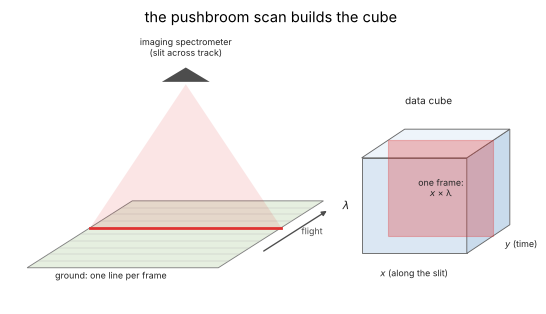

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sketch.imaging_spectrometer_layout(ax, "pushbroom", title="the pushbroom scan builds the cube")
plt.show()

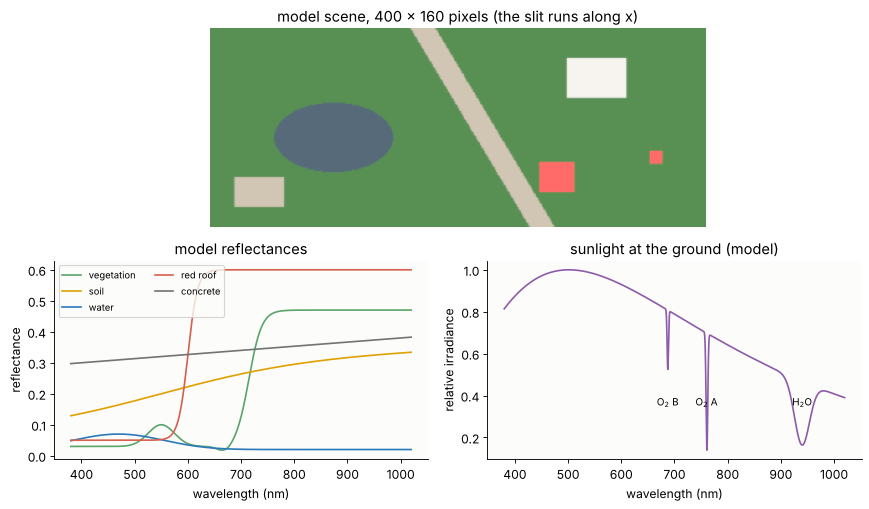

In [3]:
lam_f = np.arange(380.0, 1020.0, 0.25)                 # fine grid (nm)


def sigmoid(x):
    return 1/(1 + np.exp(-x))


def reflectances(lam):
    lam = np.asarray(lam, float)
    veg = (0.03 + 0.07*np.exp(-((lam - 550)/35)**2) - 0.02*np.exp(-((lam - 670)/20)**2)
           + 0.44*sigmoid((lam - 715)/12))
    soil = 0.08 + 0.22*sigmoid((lam - 550)/140) + 0.04*(lam - 400)/600
    water = 0.02 + 0.05*np.exp(-((lam - 470)/120)**2)*sigmoid((720 - lam)/40)
    red = 0.05 + 0.55*sigmoid((lam - 600)/9)
    concrete = 0.30 + 0.08*(lam - 400)/600
    return np.array([veg, soil, water, red, concrete])


NAMES = ["vegetation", "soil", "water", "red roof", "concrete"]
MCOL = [GREEN, ORANGE, BLUE, RED, GREY]
R_f = reflectances(lam_f)
atm = (1 - 0.80*np.exp(-0.5*((lam_f - 761)/1.6)**2)) \
    * (1 - 0.35*np.exp(-0.5*((lam_f - 687.5)/1.3)**2)) \
    * (1 - 0.65*np.exp(-0.5*((lam_f - 940)/14)**2))
E_f = planck_radiance(lam_f, 5778.0)
E_f = E_f/E_f.max()*atm                                # relative irradiance at the ground


def scene_abundances(ny, nx, soft=0.5):
    """Fractions of the five materials on an ny x nx grid (scene 1 x 0.4)."""
    y, x = np.mgrid[0:ny, 0:nx]
    u, v = (x + 0.5)/nx, 0.4*(y + 0.5)/ny
    lab = np.zeros((ny, nx), int)
    lab[np.abs((u - 0.55) - 0.6*(v - 0.2)) < 0.025] = 1                      # road
    lab[((u - 0.25)/0.12)**2 + ((v - 0.22)/0.07)**2 < 1] = 2                 # pond
    lab[(np.abs(u - 0.78) < 0.06) & (np.abs(v - 0.10) < 0.04)] = 4           # building
    lab[(np.abs(u - 0.70) < 0.035) & (np.abs(v - 0.30) < 0.03)] = 3          # roof
    lab[(np.abs(u - 0.90) < 0.012) & (np.abs(v - 0.26) < 0.012)] = 3         # small roof
    lab[(np.abs(u - 0.10) < 0.05) & (np.abs(v - 0.33) < 0.03)] = 1           # soil patch
    a = np.array([(lab == m).astype(float) for m in range(5)])
    if soft > 0:
        a = np.array([gaussian_filter(am, soft, mode="nearest") for am in a])
    return a/a.sum(0)


def rgb(a, Rm=None):
    """A quick true colour picture of an abundance map."""
    if Rm is None:
        Rm = reflectances([610, 550, 465])
    img = np.einsum("myx,mc->yxc", a, Rm)
    return np.clip(img/0.35, 0, 1)**(1/2.2)


NY, NX = 160, 400
A_scene = scene_abundances(NY, NX)

fig = plt.figure(figsize=(11, 6.5))
ax0 = fig.add_subplot(2, 1, 1)
ax0.imshow(rgb(A_scene), aspect="equal")
ax0.set_title("model scene, 400 × 160 pixels (the slit runs along x)"); ax0.axis("off")
ax1 = fig.add_subplot(2, 2, 3)
for m in range(5):
    ax1.plot(lam_f, R_f[m], color=MCOL[m], label=NAMES[m])
ax1.set_xlabel("wavelength (nm)"); ax1.set_ylabel("reflectance"); ax1.legend(fontsize=8.5, ncol=2)
ax1.set_title("model reflectances")
ax2 = fig.add_subplot(2, 2, 4)
ax2.plot(lam_f, E_f, color=PURPLE)
for l_, n_ in ((687.5, "O$_2$ B"), (761, "O$_2$ A"), (940, "H$_2$O")):
    ax2.annotate(n_, (l_, 0.35), ha="center", fontsize=9)
ax2.set_xlabel("wavelength (nm)"); ax2.set_ylabel("relative irradiance")
ax2.set_title("sunlight at the ground (model)")
plt.tight_layout(); plt.show()

## 2. Pushbroom spectrometers: smile and keystone

Both spectrometers below have a 12 mm slit, a grating of 100 lines/mm
and the same linear dispersion of about 10 µm/nm, so a detector with
30 µm pixels samples the spectrum every 3 nm (201 bands from 400 to
1000 nm) and the slit in 400 pixels.

* The **Offner** spectrometer is a concentric relay of a concave mirror
  and a convex grating. All surfaces share one centre of curvature, the
  system is symmetric about the stop on the grating, and the aberrations
  that are odd in the field, distortion included, cancel. Mouroulis
  showed that its smile and keystone can be made almost zero.
* The **Czerny–Turner** of notebook 110 (grating and prism spectrometers), here with $f$ = 100 mm and a
  long slit. The slit image is curved (the slit curvature found in
  notebook 110, grating and prism spectrometers, the grating equation for rays out of the plane of
  incidence), and the camera mirror images the slit with a
  magnification that varies with the angle of diffraction.

Smile is measured as the shift of the centroid of a slit point along
the dispersion, relative to the slit centre; keystone as the shift
along the slit relative to the centre wavelength (`smile_keystone()`).

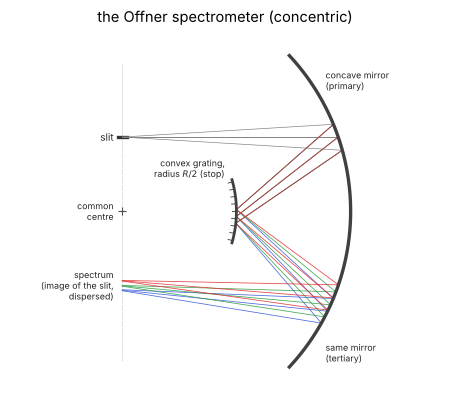

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
sketch.imaging_spectrometer_layout(ax, "offner", title="the Offner spectrometer (concentric)")
plt.show()

In [5]:
PIX = 0.030                                            # mm
wl_grid = np.linspace(400, 1000, 13)
x_slit = np.linspace(-6, 6, 9)
off = sp.offner(wavelength=700e-6, groove_density=100, order=-1, slit_length=12)
C_off = sp.centroids(off, [(x, 30.0) for x in x_slit], wl_grid*1e-6, na=0.08, n=11)
ct = sp.czerny_turner(wavelength=700e-6, groove_density=100, f_collimator=100, f_camera=100,
                      slit_height=12)
C_ct = sp.centroids(ct.system, [(x, 0.0) for x in x_slit], wl_grid*1e-6, n=11)

res = {}
for name, C in (("Offner", C_off), ("Czerny–Turner", C_ct)):
    smile, key = sp.smile_keystone(C)
    disp = np.abs(np.gradient(C[len(x_slit)//2, :, 1], wl_grid))         # mm/nm
    res[name] = dict(smile=smile, key=key, disp=disp)
    print("{:14s}: dispersion {:.2f} um/nm, max smile {:.3g} um ({:.3g} px, {:.3g} nm), "
          "max keystone {:.3g} um ({:.3g} px)".format(
              name, disp.mean()*1e3, np.abs(smile).max()*1e3, np.abs(smile).max()/PIX,
              np.abs(smile).max()/disp.mean(), np.abs(key).max()*1e3, np.abs(key).max()/PIX))
for name, s_ in (("Offner", off), ("Czerny–Turner", ct.system)):
    if name == "Offner":
        P = sp.image_points(s_, (6.0, 30.0), [400e-6, 700e-6, 1000e-6], na=0.08, n=11)
    else:
        P = sp.image_points(s_, (6.0, 0.0), [400e-6, 700e-6, 1000e-6], n=11)
    print("{:14s}: rms spot size at the slit end, 400/700/1000 nm, along / across the slit: {} um".format(
        name, ", ".join("{:.0f} / {:.0f}".format(*(np.nanstd(p, 0)*1e3)) for p in P)))

Offner        : dispersion 10.00 um/nm, max smile 0.0681 um (0.00227 px, 0.00681 nm), max keystone 0.0261 um (0.00087 px)
Czerny–Turner : dispersion 10.21 um/nm, max smile 37.6 um (1.25 px, 3.68 nm), max keystone 20.3 um (0.678 px)
Offner        : rms spot size at the slit end, 400/700/1000 nm, along / across the slit: 2 / 7, 1 / 6, 1 / 6 um


Czerny–Turner : rms spot size at the slit end, 400/700/1000 nm, along / across the slit: 128 / 121, 100 / 122, 78 / 124 um


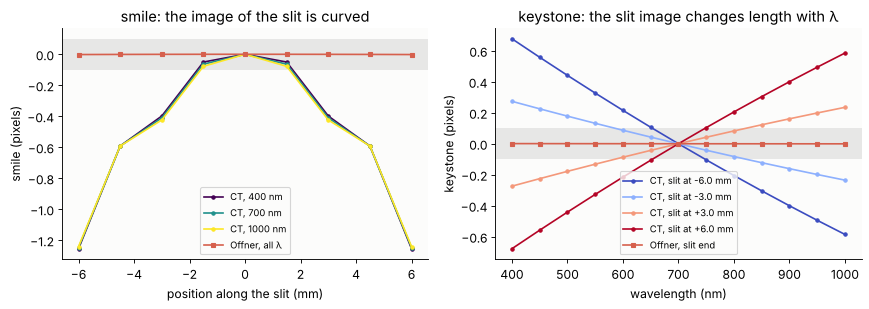

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cm = plt.cm.viridis(np.linspace(0, 1, len(wl_grid)))
for j in (0, 6, 12):
    ax[0].plot(x_slit, res["Czerny–Turner"]["smile"][:, j]/PIX, "o-", color=cm[j], ms=3,
               label="CT, {:.0f} nm".format(wl_grid[j]))
ax[0].plot(x_slit, res["Offner"]["smile"][:, 6]/PIX, "s-", color=RED, ms=3, label="Offner, all λ")
ax[0].axhspan(-0.1, 0.1, color=GREY, alpha=0.15, lw=0)
ax[0].set_xlabel("position along the slit (mm)"); ax[0].set_ylabel("smile (pixels)")
ax[0].legend(fontsize=8.5); ax[0].set_title("smile: the image of the slit is curved")
for i in (0, 2, 6, 8):
    ax[1].plot(wl_grid, res["Czerny–Turner"]["key"][i]/PIX, "o-", ms=3,
               color=plt.cm.coolwarm(i/8), label="CT, slit at {:+.1f} mm".format(x_slit[i]))
ax[1].plot(wl_grid, res["Offner"]["key"][0]/PIX, "s-", color=RED, ms=3, label="Offner, slit end")
ax[1].axhspan(-0.1, 0.1, color=GREY, alpha=0.15, lw=0)
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_ylabel("keystone (pixels)")
ax[1].legend(fontsize=8.5); ax[1].set_title("keystone: the slit image changes length with λ")
plt.tight_layout(); plt.show()

The two instruments have the same dispersion, 10.0 and 10.2 µm/nm, but
otherwise could not be more different. The Offner's smile is 0.07 µm and
its keystone 0.03 µm over the whole slit and band, a few thousandths of a
pixel, limited by the numerical noise of the centroids rather than by the
optics. Its spots are 1 to 7 µm rms, well inside a 30 µm pixel, even at
the slit end.

The Czerny–Turner's slit image is a parabola that bends 37.6 µm
(1.25 pixels, 3.7 nm) at the ends of the slit, almost the same at all
wavelengths. Its keystone grows linearly along the slit and with the
distance from the design wavelength, up to ±0.68 pixels at the ends of
slit and band: the red end of the spectrum of a pixel near the slit end
comes from two thirds of a pixel further out (or in) than the blue end.
The gray band marks the tolerance of a tenth of a pixel that Mouroulis
and coworkers give for a spectrometer whose cube can be trusted. The
centroids hide something else: at the slit end the Czerny–Turner's spots
are 80 to 130 µm rms, three to four pixels, from the astigmatism and
field curvature of its tilted spherical mirrors. A long slit is simply
not what it was designed for, and imaging spectrometers use the Offner,
the Dyson, or Czerny–Turners with corrected, freeform or toroidal mirrors
over short slits.

**What smile and keystone do to the cube.** The scene is scanned line by
line. The detector pixel $(x, k)$ of each line is assumed to see the
ground pixel $x$ at the nominal wavelength $\lambda_k$; in fact it sees
the ground at $x - \kappa(x, \lambda_k)$ (keystone, in pixels) at the
wavelength $\lambda_k + \sigma(x, \lambda_k)$ (smile, converted to nm
with the dispersion). Each band integrates the spectrum with a Gaussian
response of 3.5 nm FWHM. The reflectance is then retrieved the usual
way, by dividing by the irradiance seen at the nominal wavelengths. Any
difference from the reflectance a perfect instrument would report is
the error of the optics.

In [7]:
lam_b = np.arange(400.0, 1000.1, 3.0)
fw = 3.5


def band_filter(lam_c, y_f, fwhm):
    """Spectrum y_f (on lam_f) integrated over Gaussian bands centred at lam_c."""
    lam_c = np.asarray(lam_c, float)
    out = np.empty(lam_c.shape)
    flat = lam_c.ravel()
    o = out.ravel()
    for i0 in range(0, len(flat), 4000):
        c = flat[i0:i0 + 4000]
        w = np.exp(-4*np.log(2)*((lam_f[None, :] - c[:, None])/fwhm)**2)
        o[i0:i0 + 4000] = (w*y_f[None, :]).sum(1)/w.sum(1)
    return out


x_pix = (np.arange(NX) - (NX - 1)/2)*PIX                 # slit coordinate of each pixel (mm)
E_b = band_filter(lam_b, E_f, fw)
RE_b = np.array([band_filter(lam_b, R_f[m]*E_f, fw) for m in range(5)])
R_ideal = np.einsum("myx,mk->yxk", A_scene, RE_b)/E_b


def pushbroom_cube(r, smile_on=True, key_on=True):
    sm = RectBivariateSpline(x_slit, wl_grid, r["smile"]/r["disp"][None, :])(x_pix, lam_b)  # nm
    ky = RectBivariateSpline(x_slit, wl_grid, r["key"]/PIX)(x_pix, lam_b)                  # px
    sm = sm if smile_on else 0*sm
    ky = ky if key_on else 0*ky
    xs = np.clip(np.arange(NX)[:, None] - ky, 0, NX - 1.000001)
    i0 = np.floor(xs).astype(int)
    f = xs - i0
    cube = np.zeros((NY, NX, len(lam_b)))
    for m in range(5):
        S = band_filter(lam_b[None, :] + sm, R_f[m]*E_f, fw)                                # (NX, K)
        Am = A_scene[m][:, i0]*(1 - f) + A_scene[m][:, i0 + 1]*f                            # (NY, NX, K)
        cube += Am*S[None]
    return cube/E_b, sm, ky


cubes = {}
for name in res:
    for tag, so, ko in (("both", True, True), ("smile", True, False), ("keystone", False, True)):
        R_meas, sm, ky = pushbroom_cube(res[name], so, ko)
        cubes[(name, tag)] = R_meas - R_ideal
        if tag == "both":
            res[name]["sm_map"], res[name]["ky_map"] = sm, ky
for k_, d_ in cubes.items():
    print("{:14s} {:9s}: max |dR| {:.4f}, pixels with max |dR| > 0.01: {:.1f} %".format(
        k_[0], k_[1], np.abs(d_).max(), 100*np.mean(np.abs(d_).max(2) > 0.01)))

Offner         both     : max |dR| 0.0006, pixels with max |dR| > 0.01: 0.0 %
Offner         smile    : max |dR| 0.0006, pixels with max |dR| > 0.01: 0.0 %
Offner         keystone : max |dR| 0.0001, pixels with max |dR| > 0.01: 0.0 %
Czerny–Turner  both     : max |dR| 0.4529, pixels with max |dR| > 0.01: 74.1 %


Czerny–Turner  smile    : max |dR| 0.4529, pixels with max |dR| > 0.01: 74.0 %
Czerny–Turner  keystone : max |dR| 0.1414, pixels with max |dR| > 0.01: 1.4 %


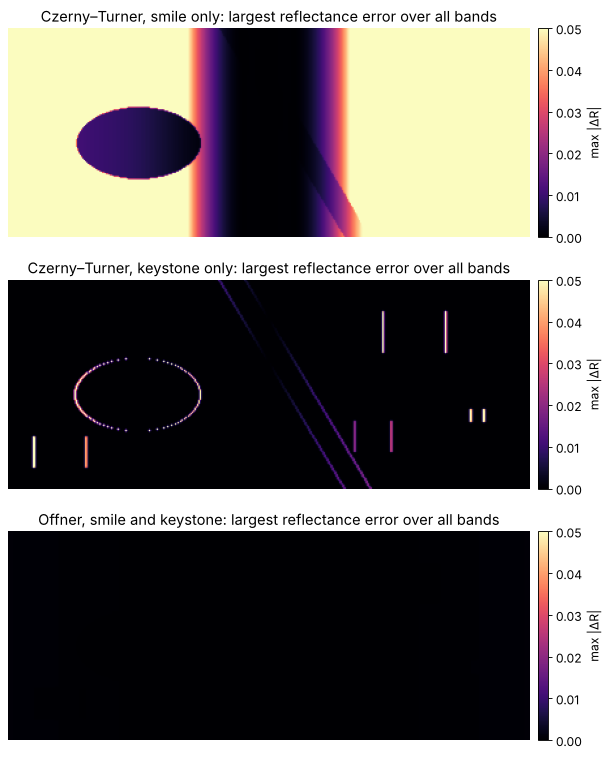

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9.6))
for a_, key_, title in zip(ax, [("Czerny–Turner", "smile"), ("Czerny–Turner", "keystone"), ("Offner", "both")],
                           ["Czerny–Turner, smile only", "Czerny–Turner, keystone only", "Offner, smile and keystone"]):
    im = a_.imshow(np.abs(cubes[key_]).max(2), vmin=0, vmax=0.05, cmap="magma")
    a_.set_title("{}: largest reflectance error over all bands".format(title)); a_.axis("off")
    plt.colorbar(im, ax=a_, fraction=0.02, pad=0.01, label="max |ΔR|")
plt.tight_layout(); plt.show()

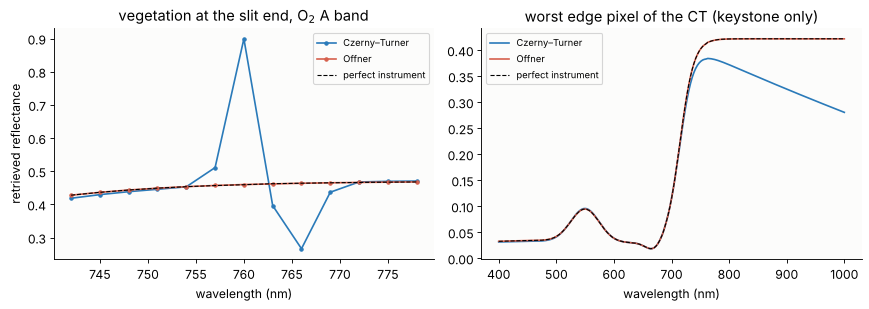

slit end pixel x = -5.89 mm: CT smile -3.42 nm, keystone -0.12 px at 761 nm
vegetation row: error < 0.01 for x from -1.19 to 1.19 mm, smile there -0.08 / -0.08 nm
CT smile error at the slit end: max |dR| 0.440 at 760 nm (R = 0.459)
worst keystone pixel (86, 51), x = -4.46 mm, materials [0.89 0.   0.11 0.   0.  ]
CT keystone error at that pixel: max |dR| 0.141 at 1000 nm


In [9]:
iy_v, ix_end = 20, 3              # vegetation at the left end of the slit
e_key = np.abs(cubes[("Czerny–Turner", "keystone")]).max(2)
row_edge, ix_edge = np.unravel_index(np.argmax(e_key), e_key.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
z = (lam_b > 740) & (lam_b < 780)
for name, c in (("Czerny–Turner", BLUE), ("Offner", RED)):
    ax[0].plot(lam_b[z], (R_ideal + cubes[(name, "both")])[iy_v, ix_end, z], "o-", ms=3, color=c,
               label=name)
ax[0].plot(lam_b[z], R_ideal[iy_v, ix_end, z], "k--", lw=1, label="perfect instrument")
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("retrieved reflectance")
ax[0].set_title("vegetation at the slit end, O$_2$ A band"); ax[0].legend(fontsize=8.5)
for name, c in (("Czerny–Turner", BLUE), ("Offner", RED)):
    ax[1].plot(lam_b, (R_ideal + cubes[(name, "keystone")])[row_edge, ix_edge, :], color=c, label=name)
ax[1].plot(lam_b, R_ideal[row_edge, ix_edge, :], "k--", lw=1, label="perfect instrument")
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_title("worst edge pixel of the CT (keystone only)")
ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print("slit end pixel x = {:.2f} mm: CT smile {:.2f} nm, keystone {:.2f} px at 761 nm".format(
    x_pix[ix_end], res["Czerny–Turner"]["sm_map"][ix_end, np.argmin(np.abs(lam_b - 761))],
    res["Czerny–Turner"]["ky_map"][ix_end, np.argmin(np.abs(lam_b - 761))]))
ok = np.abs(cubes[("Czerny–Turner", "smile")][iy_v]).max(1) < 0.01
i_ok = np.where(ok)[0]
k761 = np.argmin(np.abs(lam_b - 761))
print("vegetation row: error < 0.01 for x from {:.2f} to {:.2f} mm, smile there {:.2f} / {:.2f} nm".format(
    x_pix[i_ok[0]], x_pix[i_ok[-1]], res["Czerny–Turner"]["sm_map"][i_ok[0], k761],
    res["Czerny–Turner"]["sm_map"][i_ok[-1], k761]))
d_ = cubes[("Czerny–Turner", "smile")][iy_v, ix_end]
print("CT smile error at the slit end: max |dR| {:.3f} at {:.0f} nm (R = {:.3f})".format(
    np.abs(d_).max(), lam_b[np.argmax(np.abs(d_))], R_ideal[iy_v, ix_end, np.argmax(np.abs(d_))]))
print("worst keystone pixel ({}, {}), x = {:.2f} mm, materials {}".format(row_edge, ix_edge, x_pix[ix_edge],
      np.round(A_scene[:, row_edge, ix_edge], 2)))
d_ = cubes[("Czerny–Turner", "keystone")][row_edge, ix_edge]
print("CT keystone error at that pixel: max |dR| {:.3f} at {:.0f} nm".format(
    np.abs(d_).max(), lam_b[np.argmax(np.abs(d_))]))

**Smile** is the dangerous one. A shift of the wavelength scale does
nothing to a smooth spectrum, but next to a narrow atmospheric band the
retrieved reflectance becomes nonsense: at the end of the Czerny–Turner's
slit, where the scale is off by 3.4 nm, the vegetation shows a spike to
0.90 and a dip to 0.27 inside the O₂ A band, instead of a smooth 0.46
(error 0.44). The reflectance error stays below 0.01 only within
±1.2 mm of the slit centre, where the smile is below 0.08 nm, 3 % of a
band. Three quarters of all pixels of the scene have an error above 0.01 in
some band. This is why imaging spectrometers are calibrated column by
column, with a wavelength scale for every position on the slit, and
why the O₂ A band itself is used in flight to measure the smile.

**Keystone** errors are smaller in number (1.4 % of the pixels) but they
are where the information is: at edges. The worst pixel is a vegetation
pixel next to the pond, near the slit end, where the spectrum at
1000 nm is taken partly from the water and drops from 0.42 to 0.28.
A per-column calibration cannot remove it, because the error depends on
the scene, so the keystone must be designed out. The Offner shows
neither error above 6 × 10⁻⁴.

## 3. Filter-based cubes

A filter camera images the whole field and selects the band in front of
the detector. Three variants:

* a **filter wheel** with a handful of interference filters (notebook 113, Fabry–Perot and filters),
  here 8 bands of 25 nm FWHM, the multispectral camera of drones and
  many satellites,
* a **tunable Lyot filter** (liquid crystal tunable filter, LCTF): the
  Lyot filter of notebook 113 (Fabry–Perot and filters) with a liquid crystal retarder in every
  stage, so that the pass band can be moved electronically. Five stages
  with $\Delta n\,d$ = 1.67 µm give 7 nm FWHM at 650 nm. A tuned stage
  transmits $\cos^2(\pi\,2^k\Delta n\,d\,(1/\lambda - 1/\lambda_c))$, so the
  filter repeats in $1/\lambda$ with the period $1/(\Delta n\,d)$: its side
  orders lie inside the band of the camera and must be blocked,
* a **linear variable filter** (LVF) on the detector, whose pass band
  changes along the rows (notebook 113, Fabry–Perot and filters): every row of the detector sees a
  different wavelength, and the platform motion scans the scene across
  the rows, so every ground pixel is seen in all bands, one after the
  other.

Lyot: Delta n d = 1671 nm, side orders at 1/lambda = 1/lambda_c +- 0.00060 1/nm
tuned to 500 nm: side orders at 713, 385 nm
tuned to 650 nm: side orders at 1064, 468 nm
tuned to 850 nm: side orders at 563 nm


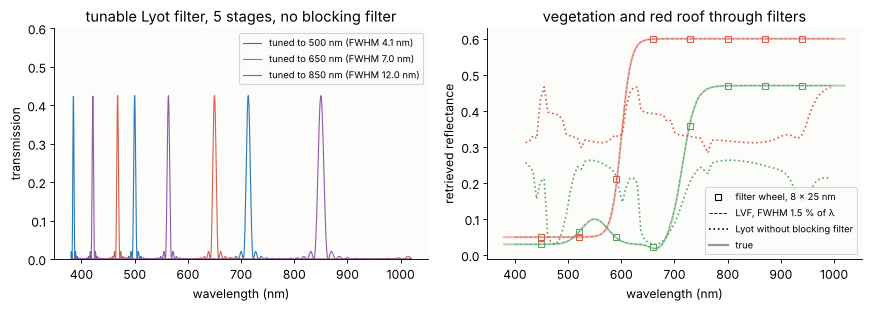

vegetation: Lyot without blocker, max error 0.322 at 938 nm
red roof: Lyot without blocker, max error 0.417 at 455 nm


In [10]:
dnd = 0.886*650.0**2/(32*7.0)       # nm, N = 5 stages, FWHM 7 nm at 650 nm
print("Lyot: Delta n d = {:.0f} nm, side orders at 1/lambda = 1/lambda_c +- {:.5f} 1/nm".format(dnd, 1/dnd))


def lyot_tuned(lam, lam_c, n_stages=5, base=dnd):
    T = np.ones_like(lam)
    for k in range(n_stages):
        T *= np.cos(np.pi*2**k*base*(1/lam - 1/lam_c))**2
    return 0.5*T*0.85                # polarizer and losses


fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lc, c in ((500, BLUE), (650, RED), (850, PURPLE)):
    T_ = lyot_tuned(lam_f, lc)
    ax[0].plot(lam_f, T_, color=c, lw=1, label="tuned to {} nm (FWHM {:.1f} nm)".format(
        lc, spc.fwhm(lam_f[np.abs(lam_f - lc) < 30], T_[np.abs(lam_f - lc) < 30])))
    side = 1/(1/lc + np.array([-1, 1])/dnd)
    print("tuned to {} nm: side orders at {} nm".format(lc, ", ".join("{:.0f}".format(s_) for s_ in side if 380 < s_ < 1100)))
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("transmission")
ax[0].legend(fontsize=8.5, loc="upper right"); ax[0].set_ylim(0, 0.6)
ax[0].set_title("tunable Lyot filter, 5 stages, no blocking filter")

wheel_c = np.linspace(450, 940, 8)
lvf_fwhm = 0.015*lam_b
lyot_c = np.arange(420.0, 1000.0, 7.0)
ivy = np.argmax(A_scene[0].ravel())
for m in (0, 3):
    RE = R_f[m]*E_f
    ax[1].plot(lam_f, R_f[m], color=MCOL[m], lw=2, alpha=0.4)
    wheel = band_filter(wheel_c, RE, 25)/band_filter(wheel_c, E_f, 25)
    ax[1].plot(wheel_c, wheel, "s", color=MCOL[m], ms=6, mfc="none")
    lv = np.array([np.sum(np.exp(-4*np.log(2)*((lam_f - lc)/w_)**2)*RE)/np.sum(np.exp(-4*np.log(2)*((lam_f - lc)/w_)**2)*E_f)
                   for lc, w_ in zip(lam_b, lvf_fwhm)])
    ax[1].plot(lam_b, lv, color=MCOL[m], lw=0.8, ls="--")
    unb = np.array([np.sum(lyot_tuned(lam_f, lc)*RE)/np.sum(lyot_tuned(lam_f, lc)*E_f) for lc in lyot_c])
    ax[1].plot(lyot_c, unb, ":", color=MCOL[m], lw=1.5)
ax[1].plot([], [], "s", color="k", mfc="none", label="filter wheel, 8 × 25 nm")
ax[1].plot([], [], "--", color="k", lw=0.8, label="LVF, FWHM 1.5 % of λ")
ax[1].plot([], [], ":", color="k", lw=1.5, label="Lyot without blocking filter")
ax[1].plot([], [], color="k", lw=2, alpha=0.4, label="true")
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_ylabel("retrieved reflectance")
ax[1].legend(fontsize=8.5); ax[1].set_title("vegetation and red roof through filters")
plt.tight_layout(); plt.show()
for m in (0, 3):
    RE = R_f[m]*E_f
    unb = np.array([np.sum(lyot_tuned(lam_f, lc)*RE)/np.sum(lyot_tuned(lam_f, lc)*E_f) for lc in lyot_c])
    print("{}: Lyot without blocker, max error {:.3f} at {:.0f} nm".format(
        NAMES[m], np.max(np.abs(unb - np.interp(lyot_c, lam_f, R_f[m]))), lyot_c[np.argmax(np.abs(unb - np.interp(lyot_c, lam_f, R_f[m])))]))

**Filter wheel.** Eight 25 nm bands follow both spectra well where they
are smooth; the red edge and the step of the roof are sampled by one or two
points. Enough to tell vegetation from paint, not enough to see the O₂ or
the shape of the red edge.

**Tunable Lyot filter.** The pass band, 7 nm at 650 nm, scales with
$\lambda^2$: 4.1 nm at 500 nm, 12 nm at 850 nm. The filter is periodic in
$1/\lambda$: tuned to 650 nm it also transmits at 468 and 1064 nm, tuned to
500 nm at 385 and 713 nm. Without a blocking filter that follows the
tuning, the reflectances retrieved from the unblocked filter are mixtures
of three wavelengths and wrong by up to 0.32 (vegetation, at 938 nm) and
0.42 (red roof, at 455 nm). Real LCTFs add more stages with a thin first
plate (a large FSR) and fixed blocking filters for each range, and
transmit only 10 to 50 % because of the polarizers.

**Linear variable filter.** The LVF, with a pass band of 1.5 % of the
wavelength, reproduces both spectra closely: the band is wider than the
pushbroom's 3.5 nm in the red (13 nm at 850 nm), but for smooth
reflectances this matters little.

**Scanning with a shaking platform.** The LVF camera records band $k$ of
a ground line when the line crosses detector row $k$, i.e. $k$ frames
after band 0. A drone or aircraft pitches and rolls, so between these
frames the ground shifts by a little more or less than one row. In the
cube the bands of one pixel then come from slightly different places,
the temporal twin of keystone. Below, the platform oscillates with an
amplitude of 0.5 pixels and a period of 50 frames, plus a random jitter
of 0.15 pixels; the bands of the LVF are spread over 201 rows.
A filter wheel has the same problem with 8 exposures instead of 201,
and a pushbroom spectrometer does not have it at all, because all bands
of a line are recorded in the same exposure.

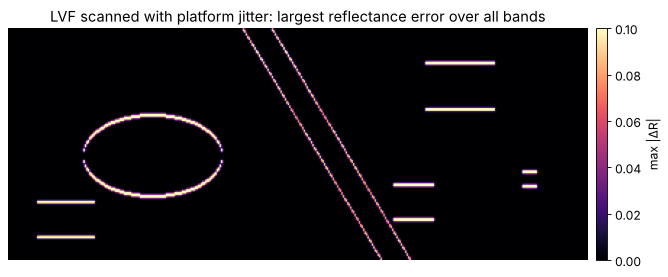

LVF jitter: max |dR| 0.273; pixels with max |dR| > 0.01: 4.3 %


In [11]:
rng = np.random.default_rng(3)
n_frames = NY + len(lam_b) + 10
t_ = np.arange(n_frames)
jit = 0.5*np.sin(2*np.pi*t_/50) + 0.15*rng.standard_normal(n_frames)
R_lvf = np.zeros_like(R_ideal)
for k in range(len(lam_b)):
    # ground row y is in detector row k at frame y + k, shifted by the jitter of that frame
    ys = np.clip(np.arange(NY) + jit[np.arange(NY) + k], 0, NY - 1.000001)
    i0 = np.floor(ys).astype(int); f = ys - i0
    A_k = A_scene[:, i0, :]*(1 - f)[None, :, None] + A_scene[:, i0 + 1, :]*f[None, :, None]
    R_lvf[:, :, k] = np.einsum("myx,m->yx", A_k, RE_b[:, k])/E_b[k]
err_lvf = np.abs(R_lvf - R_ideal).max(2)
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(err_lvf, vmin=0, vmax=0.1, cmap="magma")
ax.set_title("LVF scanned with platform jitter: largest reflectance error over all bands"); ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="max |ΔR|")
plt.tight_layout(); plt.show()
print("LVF jitter: max |dR| {:.3f}; pixels with max |dR| > 0.01: {:.1f} %".format(err_lvf.max(), 100*np.mean(err_lvf > 0.01)))

**The light budget.** Take a cube of $N \times N$ pixels and $K$ bands,
recorded in a total time $T$ with the same detector and the same
optics (the same f-number and pixel). The table counts the photons
collected per voxel, relative to an ideal instrument that sees every
voxel for the whole time $T$ through a perfect filter of one band
width, and the efficiency of the spectral element.

In [12]:
N, K = 400, 201
rows = [
    ("pushbroom (grating, 50 %)", 1/N, 0.5, "1 line per frame, all bands at once"),
    ("filter wheel, 8 bands (90 %)", 1/8, 0.9, "8 broad bands only"),
    ("Lyot / LCTF, K bands (40 %)", 1/K, 0.4, "polarizer loses half"),
    ("LVF on the detector (80 %)", 1/(N + K), 0.8, "one frame per band and line"),
    ("CASSI (mask 50 %, prism 90 %)", 1.0, 0.45, "all voxels at once, multiplexed"),
]
print("{:34s} {:>11s} {:>11s} {:>12s}".format("method", "time/voxel", "efficiency", "photons rel."))
for name, tf, eff, note in rows:
    print("{:34s} {:11.4f} {:11.2f} {:12.5f}".format(name, tf, eff, tf*eff))

method                              time/voxel  efficiency photons rel.
pushbroom (grating, 50 %)               0.0025        0.50      0.00125
filter wheel, 8 bands (90 %)            0.1250        0.90      0.11250
Lyot / LCTF, K bands (40 %)             0.0050        0.40      0.00199
LVF on the detector (80 %)              0.0017        0.80      0.00133
CASSI (mask 50 %, prism 90 %)           1.0000        0.45      0.45000


The pushbroom spectrometer and the LVF collect about the same number
of photons per voxel ($T/N$ and $T/(N+K)$), the LVF somewhat more for its
efficient filter. The tunable filter is even a little ahead, because
$K$ = 201 bands take less time than $N$ = 400 lines, despite losing half
the light at the polarizer; but it reads all
bands in sequence, so a moving scene (clouds, leaves, a drone) smears
along the spectrum, which the pushbroom does not. The filter wheel looks
two orders of magnitude better only because it measures 8 bands instead
of 201.

CASSI collects 0.45 of the light of every voxel for the whole time, two
orders of magnitude more than the scanning instruments. It pays in
another currency: the detector records 33 times fewer numbers than the
cube has voxels, and each pixel is a sum of 40 bands. As in the
Fellgett comparison of notebook 111 (Fourier transform spectroscopy), multiplexing helps when the noise
is detector noise (dim scenes, fast frame rates, the infrared) and does
little when it is photon noise. The real price is the prior that the
reconstruction needs, which the next section shows.

## 4. Snapshot: the coded aperture snapshot spectral imager

CASSI (Wagadarikar, John, Willett and Brady 2008) records the whole cube
in one exposure. A telescope images the scene onto a binary random
mask; a relay with a prism (or grating) disperses the masked image, so
that band $k$ lands shifted by $k$ pixels along $x$; the detector sums
all bands:

$$ g(y, x) = \sum_k M(y, x - k)\,f(y, x - k, k). $$

The detector has $N_y(N_x + K - 1)$ pixels for $N_y N_x K$ unknowns, a
compression of almost $K$:1. Without the mask the problem would be
hopeless: a bright spot at $(x, k)$ and at $(x + 1, k - 1)$ look the same.
The mask gives every band of every pixel a different code, and the
reconstruction relies on the scene being simple: images of each band
with sharp edges and flat areas, i.e. a small total variation, the prior
that also served the diffuser camera of notebook 79 (lensless imaging). `gap_tv()`
alternates the exact projection onto the measurements (cheap, because
$\Phi\Phi^T$ is diagonal) with a total variation denoising step
(generalized alternating projection, GAP-TV).

The scene is the same model at half the resolution, 200 × 80 pixels, with 40 bands of 15 nm
from 415 to 1000 nm, and the detector adds noise of 0.5 % of its
mean signal.

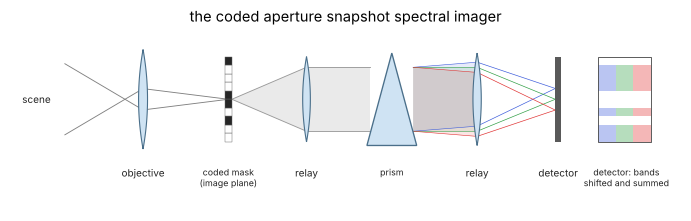

In [13]:
fig, ax = plt.subplots(figsize=(11, 3))
sketch.imaging_spectrometer_layout(ax, "cassi", title="the coded aperture snapshot spectral imager")
plt.show()

In [14]:
NCY, NCX, KC = 80, 200, 40
lam_c = np.linspace(415.0, 1000.0, KC)
A_c = scene_abundances(NCY, NCX)
RE_c = np.array([band_filter(lam_c, R_f[m]*E_f, 15.0) for m in range(5)])
E_c = band_filter(lam_c, E_f, 15.0)
cube_true = np.einsum("myx,mk->yxk", A_c, RE_c/E_c)       # reflectance cube (flat-fielded)
mask = (rng.random((NCY, NCX)) < 0.5).astype(float)
g_clean = sp.cassi_forward(cube_true, mask, 1)
g = g_clean + 0.005*g_clean.mean()*rng.standard_normal(g_clean.shape)

hist = []
t0 = time.time()
rec = sp.gap_tv(g, mask, KC, 1, weight=0.05, n_iter=100, tv_iter=10,
                callback=lambda i, x: hist.append(np.sqrt(np.mean((x - cube_true)**2))))
t_rec = time.time() - t0
R_ = sp.cassi_forward(np.ones_like(cube_true), mask, 1); R_[R_ == 0] = 1
x_ls = sp.cassi_adjoint(g/R_, mask, KC, 1)
rmse = lambda x: np.sqrt(np.mean((x - cube_true)**2))
psnr = lambda x: 20*np.log10(cube_true.max()/rmse(x))
print("detector {} pixels for {} unknowns (ratio {:.1f})".format(g.size, cube_true.size, cube_true.size/g.size))
print("first projection (min norm): RMSE {:.4f}, PSNR {:.1f} dB".format(rmse(x_ls), psnr(x_ls)))
print("GAP-TV, 100 iterations ({:.0f} s): RMSE {:.4f}, PSNR {:.1f} dB".format(t_rec, rmse(rec), psnr(rec)))
sam = np.degrees(np.arccos(np.clip(np.sum(rec*cube_true, 2)/np.linalg.norm(rec, axis=2)/np.linalg.norm(cube_true, axis=2), -1, 1)))
print("spectral angle: median {:.1f} deg, 90th percentile {:.1f} deg".format(np.median(sam), np.percentile(sam, 90)))

detector 19120 pixels for 640000 unknowns (ratio 33.5)
first projection (min norm): RMSE 0.2529, PSNR 7.5 dB
GAP-TV, 100 iterations (29 s): RMSE 0.0317, PSNR 25.5 dB
spectral angle: median 1.8 deg, 90th percentile 14.6 deg


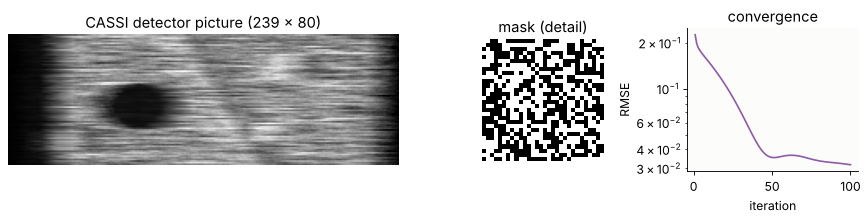

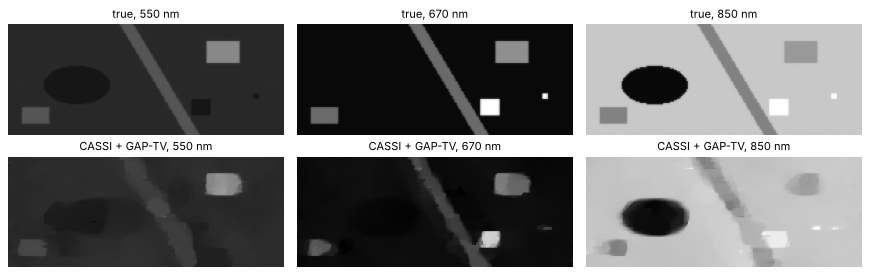

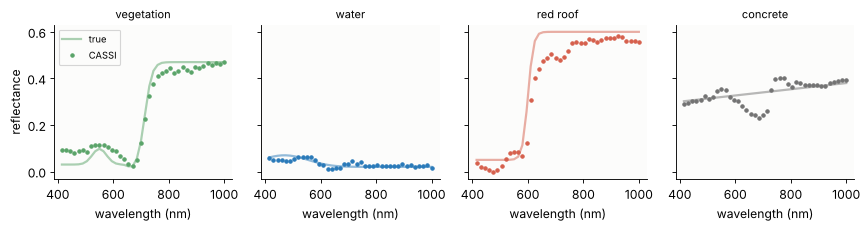

pixel (10, 100): materials [1. 0. 0. 0. 0.], rms spectral error 0.0371
pixel (44, 50): materials [0. 0. 1. 0. 0.], rms spectral error 0.0117
pixel (60, 140): materials [0. 0. 0. 1. 0.], rms spectral error 0.0719
pixel (20, 156): materials [0. 0. 0. 0. 1.], rms spectral error 0.0408
rms error: flat areas 0.0170, edges 0.0582


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(11, 2.9), gridspec_kw=dict(width_ratios=[3.2, 1, 1.4]))
ax[0].imshow(g, cmap="gray"); ax[0].set_title("CASSI detector picture (239 × 80)"); ax[0].axis("off")
ax[1].imshow(mask[:30, :30], cmap="gray"); ax[1].set_title("mask (detail)"); ax[1].axis("off")
ax[2].semilogy(np.arange(1, len(hist) + 1), hist, color=PURPLE)
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("RMSE"); ax[2].set_title("convergence")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(11, 3.6))
for j, lk in enumerate((550, 670, 850)):
    k = np.argmin(np.abs(lam_c - lk))
    ax[0, j].imshow(cube_true[:, :, k], cmap="gray", vmin=0, vmax=0.6)
    ax[0, j].set_title("true, {:.0f} nm".format(lam_c[k]), fontsize=10); ax[0, j].axis("off")
    ax[1, j].imshow(rec[:, :, k], cmap="gray", vmin=0, vmax=0.6)
    ax[1, j].set_title("CASSI + GAP-TV, {:.0f} nm".format(lam_c[k]), fontsize=10); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

pts = [(10, 100, 0), (int(0.55*NCY), int(0.25*NCX), 2), (int(0.75*NCY), int(0.70*NCX), 3),
       (int(0.25*NCY), int(0.78*NCX), 4)]
fig, ax = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for a_, (yy, xx, m) in zip(ax, pts):
    a_.plot(lam_c, cube_true[yy, xx], color=MCOL[m], lw=2, alpha=0.5, label="true")
    a_.plot(lam_c, rec[yy, xx], "o", color=MCOL[m], ms=3, label="CASSI")
    a_.set_title(NAMES[m], fontsize=10); a_.set_xlabel("wavelength (nm)")
ax[0].set_ylabel("reflectance"); ax[0].legend(fontsize=8.5)
plt.tight_layout(); plt.show()
for (yy, xx, c) in pts:
    print("pixel ({}, {}): materials {}, rms spectral error {:.4f}".format(
        yy, xx, np.round(A_c[:, yy, xx], 2), np.sqrt(np.mean((rec[yy, xx] - cube_true[yy, xx])**2))))
edge = np.zeros((NCY, NCX), bool)
for m in range(5):
    gy, gx = np.gradient(A_c[m]); edge |= np.hypot(gy, gx) > 0.05
err_px = np.sqrt(np.mean((rec - cube_true)**2, 2))
print("rms error: flat areas {:.4f}, edges {:.4f}".format(err_px[~edge].mean(), err_px[edge].mean()))

The detector picture is the masked scene smeared along $x$ by the
dispersion: the pond and the roofs are recognisable, but no band is.
The first projection (the minimum norm solution of $\Phi x = g$) is
useless, with a peak signal to noise ratio of 7.5 dB. GAP-TV reaches
25.5 dB after 100 iterations (about half a minute here); more iterations or
other weights did not go below an RMSE of 0.029 in tests, the limit set
by the ambiguity of the measurement.

The images of single bands are recognisable, with the blocky edges that
total variation prefers, and with some structure leaking from one band
into its neighbours at the edges. The spectra show
the typical failure of CASSI: the shapes of all four spectra are right
to first order, but the vegetation's green peak is smeared out and its
blue is too bright, the plateau of the roof is 0.02 to 0.05 low, and
the concrete gets a spurious dip near 680 nm. The spectral
angle to the true spectrum has a median of 1.8° but a 90th percentile of
15°; the rms error is 0.017 in flat areas and 0.058 at edges.

CASSI is therefore at its best for scenes that change too fast for
scanning, where a fair cube in one exposure beats a perfect one that comes
too late: live tissue, combustion, moving vehicles. Learned priors (deep
unrolled networks) have replaced total variation in recent work and do
much better on natural scenes; dual-disperser designs and several
exposures with different masks reduce the ambiguity itself.

## Summary

* An Offner spectrometer, concentric and symmetric, has smile and keystone
  of a few thousandths of a pixel over a 12 mm slit and 400 to 1000 nm,
  with spots of 1 to 7 µm. A Czerny–Turner of the same dispersion has
  1.25 pixels of smile and ±0.68 pixels of keystone, and spots of three to
  four pixels at the slit end.
* Smile shifts the wavelength scale and ruins reflectances in narrow
  atmospheric bands: 0.44 in the O₂ A band at 3.4 nm shift, and already
  0.01 at 0.08 nm. Keystone mixes neighbouring ground pixels with a
  weight that changes along the spectrum, up to 0.14 at edges, and cannot
  be calibrated away.
* Filter cameras trade spectral resolution (filter wheel), sequential
  exposure and side orders (Lyot, transmitting at 468 and 1064 nm when
  tuned to 650 nm), or temporal misregistration with a shaking platform
  (LVF, errors up to 0.27 at edges) for simplicity.
* CASSI records a 200 × 80 × 40 cube in one exposure of 239 × 80 pixels.
  GAP-TV recovers it to 25.5 dB with good images and fair spectra
  (median spectral angle 1.8°), at the cost of a total variation prior
  that blurs spectral detail and fails at edges.

In [16]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 152 s


## References

* P. Mouroulis, R. O. Green and T. G. Chrien, "Design of pushbroom
  imaging spectrometers for optimum recovery of spectroscopic and spatial
  information", Appl. Opt. 39, 2210–2220 (2000).
* A. Offner, "New concepts in projection mask aligners", Opt. Eng. 14,
  130–132 (1975).
* R. O. Green et al., "Imaging spectroscopy and the Airborne
  Visible/Infrared Imaging Spectrometer (AVIRIS)", Remote Sens. Environ.
  65, 227–248 (1998).
* N. Gat, "Imaging spectroscopy using tunable filters: a review",
  Proc. SPIE 4056, 50–64 (2000).
* A. Wagadarikar, R. John, R. Willett and D. Brady, "Single disperser
  design for coded aperture snapshot spectral imaging", Appl. Opt. 47,
  B44–B51 (2008).
* X. Yuan, "Generalized alternating projection based total variation
  minimization for compressive sensing", Proc. IEEE ICIP, 2539–2543
  (2016).
* N. Hagen and M. W. Kudenov, "Review of snapshot spectral imaging
  technologies", Opt. Eng. 52, 090901 (2013).